# Telecom Churn

### Author : Mayank Shekhar and Reshma Shenoy

**Business Problem:** In the telecom industry, customers are able to choose from multiple service providers and actively switch from one operator to another. In this highly competitive market, the telecommunications industry experiences an average of 15-25% annual churn rate. Given the fact that it costs 5-10 times more to acquire a new customer than to retain an existing one, customer retention has now become even more important than customer acquisition.

**Approach:** Here is the approach I will be taking to solve this problem.
1. Data Preparation and analysis : 
   - Loading of data
   - Elimination of Columns not useful for our problem or is strictly dependent
   - Extracting High Value Customers
   - Adding Churn Column with business insights
2. Feature engineering on data :
   - Spliting of Data into Train and Test
   - Scaling of Data
3. Variable Selection : 
   - Use RFE to exculde large number of Variables which is not significant
   - Use Manaual Approach to remove more variables on basis of P - Value and VIF
4. Bulid Final Model and Model Efficiency :
   - Build Final Model
       - Logistic Regression Using RFE
       - Logistic Regression Using PCA
       - Random Forest Using PCA

In [169]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import seaborn as sns
from sklearn.model_selection import train_test_split
import warnings
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from sklearn import metrics

sns.set(style='darkgrid')
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 2)
pd.set_option('display.max_rows', 600)
pd.set_option('display.max_columns', 600)
pd.set_option('display.width', 10000)
pd.set_option('display.max_colwidth',1000)

In [125]:
#reading data
data = pd.read_csv('telecom_churn_data.csv')
data=data.set_index('mobile_number')

In [126]:
#dropping date columns and circle id as it is having only one value
date_col_list = list(data.select_dtypes(exclude=['float64','int64']).columns)
data=data.drop(date_col_list,axis=1)
data.fillna(value=0,axis=1,inplace=True)
data=data.drop('circle_id',axis=1)

In [127]:
col_list=list(data.columns)
col_with_single_values=[]
for i in range(data.shape[1]):
    if len(data.iloc[:,i].unique())==1:
        col_with_single_values.append(col_list[i])

data=data.drop(col_with_single_values,axis=1)

In [128]:
list(data.columns)

['arpu_6',
 'arpu_7',
 'arpu_8',
 'arpu_9',
 'onnet_mou_6',
 'onnet_mou_7',
 'onnet_mou_8',
 'onnet_mou_9',
 'offnet_mou_6',
 'offnet_mou_7',
 'offnet_mou_8',
 'offnet_mou_9',
 'roam_ic_mou_6',
 'roam_ic_mou_7',
 'roam_ic_mou_8',
 'roam_ic_mou_9',
 'roam_og_mou_6',
 'roam_og_mou_7',
 'roam_og_mou_8',
 'roam_og_mou_9',
 'loc_og_t2t_mou_6',
 'loc_og_t2t_mou_7',
 'loc_og_t2t_mou_8',
 'loc_og_t2t_mou_9',
 'loc_og_t2m_mou_6',
 'loc_og_t2m_mou_7',
 'loc_og_t2m_mou_8',
 'loc_og_t2m_mou_9',
 'loc_og_t2f_mou_6',
 'loc_og_t2f_mou_7',
 'loc_og_t2f_mou_8',
 'loc_og_t2f_mou_9',
 'loc_og_t2c_mou_6',
 'loc_og_t2c_mou_7',
 'loc_og_t2c_mou_8',
 'loc_og_t2c_mou_9',
 'loc_og_mou_6',
 'loc_og_mou_7',
 'loc_og_mou_8',
 'loc_og_mou_9',
 'std_og_t2t_mou_6',
 'std_og_t2t_mou_7',
 'std_og_t2t_mou_8',
 'std_og_t2t_mou_9',
 'std_og_t2m_mou_6',
 'std_og_t2m_mou_7',
 'std_og_t2m_mou_8',
 'std_og_t2m_mou_9',
 'std_og_t2f_mou_6',
 'std_og_t2f_mou_7',
 'std_og_t2f_mou_8',
 'std_og_t2f_mou_9',
 'std_og_mou_6',
 'std_o

In [129]:
#extracting high value customers
data['total_rech_6']=data['total_rech_amt_6']+data['total_rech_data_6']*data['av_rech_amt_data_6']
data['total_rech_7']=data['total_rech_amt_7']+data['total_rech_data_7']*data['av_rech_amt_data_7']
data['total_rech_good_phs']=data[['total_rech_6','total_rech_7']].mean(axis=1)
seventh_quantitle = math.ceil(data['total_rech_good_phs'].quantile(q=0.7))
data=data[data['total_rech_good_phs']>=seventh_quantitle]
data.shape

(30001, 204)

In [130]:
#adding churn columns
# adding churn column as 0/1
data['churn']=0
data.loc[(data['total_og_mou_9']==0)&(data['total_ic_mou_9']==0)&(data['vol_2g_mb_9'] + data['vol_3g_mb_9']==0),'churn']=1

In [131]:
#dropping month 9 columns
churn_phase_col=[x for x in list(data.columns) if '_9' in x]
data=data.drop(churn_phase_col,axis=1)

In [133]:
X=data.drop(['churn'],axis=1)
y=data.pop('churn')

In [134]:
#Splitting Columns
X_train,X_test,y_train,y_test = train_test_split(X,y, train_size=0.7,test_size=0.3,random_state=100)

In [135]:
#scaling
scaler = StandardScaler()
X_train[X_train.columns]=scaler.fit_transform(X_train[X_train.columns])
X_test[X_train.columns]=scaler.transform(X_test[X_train.columns])

In [136]:
X_train.shape

(21000, 155)

In [139]:
#Running RFE to find top 30 variables from 155.
lr = LogisticRegression(class_weight='balanced')
lr.fit(X_train, y_train)

rfe = RFE(lr, 30)             # running RFE
rfe = rfe.fit(X_train, y_train)

#listing all columns with there rank in order of importance
list(zip(X_train.columns,rfe.support_,rfe.ranking_))

[('arpu_6', False, 32),
 ('arpu_7', False, 13),
 ('arpu_8', True, 1),
 ('onnet_mou_6', False, 9),
 ('onnet_mou_7', False, 11),
 ('onnet_mou_8', True, 1),
 ('offnet_mou_6', False, 74),
 ('offnet_mou_7', True, 1),
 ('offnet_mou_8', False, 54),
 ('roam_ic_mou_6', False, 47),
 ('roam_ic_mou_7', False, 100),
 ('roam_ic_mou_8', False, 126),
 ('roam_og_mou_6', False, 75),
 ('roam_og_mou_7', True, 1),
 ('roam_og_mou_8', False, 103),
 ('loc_og_t2t_mou_6', False, 46),
 ('loc_og_t2t_mou_7', False, 78),
 ('loc_og_t2t_mou_8', False, 36),
 ('loc_og_t2m_mou_6', False, 10),
 ('loc_og_t2m_mou_7', False, 12),
 ('loc_og_t2m_mou_8', True, 1),
 ('loc_og_t2f_mou_6', False, 79),
 ('loc_og_t2f_mou_7', False, 87),
 ('loc_og_t2f_mou_8', False, 104),
 ('loc_og_t2c_mou_6', False, 39),
 ('loc_og_t2c_mou_7', False, 52),
 ('loc_og_t2c_mou_8', False, 42),
 ('loc_og_mou_6', False, 117),
 ('loc_og_mou_7', False, 55),
 ('loc_og_mou_8', True, 1),
 ('std_og_t2t_mou_6', False, 45),
 ('std_og_t2t_mou_7', True, 1),
 ('std_og

In [140]:
rfe_col=X_train.columns[rfe.support_]
rfe_col

Index(['arpu_8', 'onnet_mou_8', 'offnet_mou_7', 'roam_og_mou_7', 'loc_og_t2m_mou_8', 'loc_og_mou_8', 'std_og_t2t_mou_7', 'std_og_t2t_mou_8', 'total_og_mou_7', 'total_og_mou_8', 'loc_ic_t2m_mou_7', 'loc_ic_mou_8', 'std_ic_t2t_mou_7', 'std_ic_t2t_mou_8', 'total_ic_mou_6', 'total_ic_mou_8', 'total_rech_num_8', 'total_rech_amt_8', 'last_day_rch_amt_8', 'total_rech_data_6', 'total_rech_data_8', 'count_rech_2g_8', 'av_rech_amt_data_6', 'vol_2g_mb_8', 'arpu_2g_6', 'monthly_2g_8', 'monthly_3g_8', 'fb_user_8', 'aon', 'sep_vbc_3g'], dtype='object')

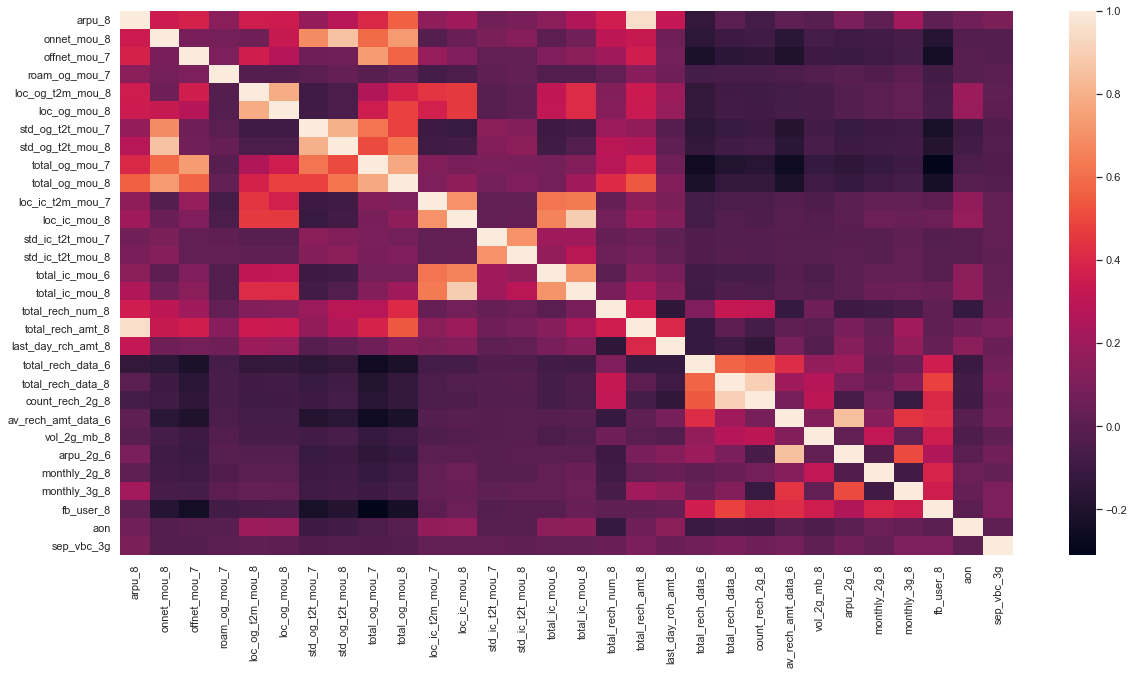

In [142]:
plt.figure(figsize = (20,10))        # Size of the figure
sns.heatmap(data[rfe_col].corr())
plt.show()

In [180]:
#Defining some funtions
def get_model(X,y):
    """
        This method will print summary of Logistic model and return Logistic Model object.
        Parameters:
                   X: DataFrame of independent Variables
                   y: DataFrame of Dependent Variables

        Returns Logistic Model Object
    """
    X_lm = sm.add_constant(X)
    lr = sm.GLM(y, X_lm, family = sm.families.Binomial()).fit()
    print(lr.summary())
    return lr

def print_VIF(X):
    """
        This method will print VIF.
        Parameters:
                   X: DataFrame of Variables for which you want to check VIF.

        Returns None
    """
    vif = pd.DataFrame()
    vif['Features'] = X.columns
    vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    vif['VIF'] = round(vif['VIF'], 2)
    vif = vif.sort_values(by = "VIF", ascending = False)
    print(vif)
    
def draw_roc( actual, probs ):
    fpr, tpr, thresholds = metrics.roc_curve( actual, probs,
                                              drop_intermediate = False )
    auc_score = metrics.roc_auc_score( actual, probs )
    plt.figure(figsize=(5, 5))
    plt.plot( fpr, tpr, label='ROC curve (area = %0.2f)' % auc_score )
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver operating characteristic example')
    plt.legend(loc="lower right")
    plt.show()
    return None



### Manual Elimination of features

In [151]:
X_train_lr = X_train[rfe_col]
lr = get_model(X_train_lr,y_train)
print_VIF(X_train_lr)

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  churn   No. Observations:                21000
Model:                            GLM   Df Residuals:                    20969
Model Family:                Binomial   Df Model:                           30
Link Function:                  logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3901.5
Date:                Sun, 22 Nov 2020   Deviance:                       7802.9
Time:                        20:28:21   Pearson chi2:                 3.42e+05
No. Iterations:                    10                                         
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -4.3649      0

#### Removing loc_og_mou_8

In [152]:
X_train_lr = X_train_lr.drop('loc_og_mou_8',axis=1)
lr = get_model(X_train_lr,y_train)
print_VIF(X_train_lr)

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  churn   No. Observations:                21000
Model:                            GLM   Df Residuals:                    20970
Model Family:                Binomial   Df Model:                           29
Link Function:                  logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3901.6
Date:                Sun, 22 Nov 2020   Deviance:                       7803.2
Time:                        20:28:25   Pearson chi2:                 3.41e+05
No. Iterations:                    10                                         
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -4.3639      0

#### Removing total_rech_amt_8

In [153]:
X_train_lr = X_train_lr.drop('total_rech_amt_8',axis=1)
lr = get_model(X_train_lr,y_train)
print_VIF(X_train_lr)

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  churn   No. Observations:                21000
Model:                            GLM   Df Residuals:                    20971
Model Family:                Binomial   Df Model:                           28
Link Function:                  logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3901.8
Date:                Sun, 22 Nov 2020   Deviance:                       7803.6
Time:                        20:29:03   Pearson chi2:                 3.47e+05
No. Iterations:                    10                                         
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -4.3611      0

#### Removing offnet_mou_7

In [154]:
X_train_lr = X_train_lr.drop('offnet_mou_7',axis=1)
lr = get_model(X_train_lr,y_train)
print_VIF(X_train_lr)

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  churn   No. Observations:                21000
Model:                            GLM   Df Residuals:                    20972
Model Family:                Binomial   Df Model:                           27
Link Function:                  logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3902.2
Date:                Sun, 22 Nov 2020   Deviance:                       7804.5
Time:                        20:29:36   Pearson chi2:                 3.95e+05
No. Iterations:                    10                                         
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -4.3578      0

#### Removing onnet_mou_8

In [155]:
X_train_lr = X_train_lr.drop('onnet_mou_8',axis=1)
lr = get_model(X_train_lr,y_train)
print_VIF(X_train_lr)

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  churn   No. Observations:                21000
Model:                            GLM   Df Residuals:                    20973
Model Family:                Binomial   Df Model:                           26
Link Function:                  logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3902.5
Date:                Sun, 22 Nov 2020   Deviance:                       7804.9
Time:                        20:30:12   Pearson chi2:                 4.05e+05
No. Iterations:                    10                                         
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -4.3566      0

#### Removing total_rech_data_8

In [156]:
X_train_lr = X_train_lr.drop('total_rech_data_8',axis=1)
lr = get_model(X_train_lr,y_train)
print_VIF(X_train_lr)

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  churn   No. Observations:                21000
Model:                            GLM   Df Residuals:                    20974
Model Family:                Binomial   Df Model:                           25
Link Function:                  logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3903.6
Date:                Sun, 22 Nov 2020   Deviance:                       7807.3
Time:                        20:30:44   Pearson chi2:                 4.59e+05
No. Iterations:                    10                                         
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -4.3514      0

#### Removing loc_ic_mou_8

In [157]:
X_train_lr = X_train_lr.drop('loc_ic_mou_8',axis=1)
lr = get_model(X_train_lr,y_train)
print_VIF(X_train_lr)

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  churn   No. Observations:                21000
Model:                            GLM   Df Residuals:                    20975
Model Family:                Binomial   Df Model:                           24
Link Function:                  logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3922.2
Date:                Sun, 22 Nov 2020   Deviance:                       7844.3
Time:                        20:31:21   Pearson chi2:                 8.86e+05
No. Iterations:                    10                                         
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -4.2803      0

#### Removing std_ic_t2t_mou_8

In [158]:
X_train_lr = X_train_lr.drop('std_ic_t2t_mou_8',axis=1)
lr = get_model(X_train_lr,y_train)
print_VIF(X_train_lr)

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  churn   No. Observations:                21000
Model:                            GLM   Df Residuals:                    20976
Model Family:                Binomial   Df Model:                           23
Link Function:                  logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3922.2
Date:                Sun, 22 Nov 2020   Deviance:                       7844.4
Time:                        20:31:52   Pearson chi2:                 9.07e+05
No. Iterations:                    10                                         
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -4.2809      0

In [159]:
X_train_lr.columns

Index(['arpu_8', 'roam_og_mou_7', 'loc_og_t2m_mou_8', 'std_og_t2t_mou_7', 'std_og_t2t_mou_8', 'total_og_mou_7', 'total_og_mou_8', 'loc_ic_t2m_mou_7', 'std_ic_t2t_mou_7', 'total_ic_mou_6', 'total_ic_mou_8', 'total_rech_num_8', 'last_day_rch_amt_8', 'total_rech_data_6', 'count_rech_2g_8', 'av_rech_amt_data_6', 'vol_2g_mb_8', 'arpu_2g_6', 'monthly_2g_8', 'monthly_3g_8', 'fb_user_8', 'aon', 'sep_vbc_3g'], dtype='object')

In [161]:
lr = LogisticRegression(class_weight='balanced')
model_lr = lr.fit(X_train_lr, y_train)

In [170]:
y_train_pred=model_lr.predict(X_train_lr)
y_train_pred_final = pd.DataFrame({'Churn':y_train.values, 'Churn_Pred':y_train_pred})
y_train_pred_final['mobile_number'] = y_train.index
y_train_pred_final.head()

,Churn,Churn_Pred,mobile_number
0,0,0,7001454064
1,0,0,7001929370
2,0,0,7000952221
3,0,0,7000752154
4,0,0,7000346259


In [166]:
y_test_pred = model_lr.predict(X_test[X_train_lr.columns])

In [179]:
# Confusion matrix 
confusion = metrics.confusion_matrix(y_train_pred_final.Churn, y_train_pred_final.Churn_Pred )
print(confusion)
print('Accuracy : {:.2f}'.format(metrics.accuracy_score(y_train_pred_final.Churn, y_train_pred_final.Churn_Pred)))
print('Precision Score : {:.2f}'.format(metrics.precision_score(y_train_pred_final.Churn, y_train_pred_final.Churn_Pred)))
print('Recall : {:.2f}'.format(metrics.recall_score(y_train_pred_final.Churn, y_train_pred_final.Churn_Pred)))
print('F1 Score : {:.2f}'.format(metrics.f1_score(y_train_pred_final.Churn, y_train_pred_final.Churn_Pred)))

[[15485  3824]
 [  276  1415]]
Accuracy : 0.80
Precision Score : 0.27
Recall : 0.84
F1 Score : 0.41


In [181]:
fpr, tpr, thresholds = metrics.roc_curve( y_train_pred_final.Churn, y_train_pred_final.Churn_Pred, drop_intermediate = False )

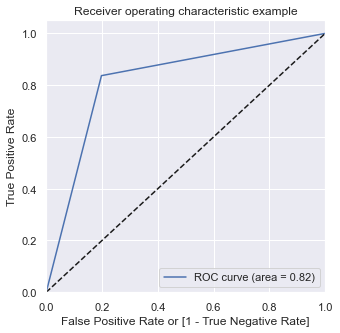

In [184]:
draw_roc(y_train_pred_final.Churn, y_train_pred_final.Churn_Pred)

We can see the Accuracy is 80% and Recall is 84% which is quite good model. So, we can consider the features in this model for our management to find the usefull insights and take appropriate actions.

In [185]:
X_train_lr.columns

Index(['arpu_8', 'roam_og_mou_7', 'loc_og_t2m_mou_8', 'std_og_t2t_mou_7', 'std_og_t2t_mou_8', 'total_og_mou_7', 'total_og_mou_8', 'loc_ic_t2m_mou_7', 'std_ic_t2t_mou_7', 'total_ic_mou_6', 'total_ic_mou_8', 'total_rech_num_8', 'last_day_rch_amt_8', 'total_rech_data_6', 'count_rech_2g_8', 'av_rech_amt_data_6', 'vol_2g_mb_8', 'arpu_2g_6', 'monthly_2g_8', 'monthly_3g_8', 'fb_user_8', 'aon', 'sep_vbc_3g'], dtype='object')

Some insights from above columns we can conclude : 
    - roam_og_mou_7 : We can see that customer is using roaming in outgoing calls, if we introduce some new roaming packs for these customers.
    - last_day_rch_amt_8 : If we can provide some last minute notification, just before the month of churn.
    - Also we can provide some offer scheme just before the churn month

# Modeling Using PCA

In [186]:
from sklearn.decomposition import PCA
pca = PCA(random_state=42)
pca.fit(X_train)

PCA(random_state=42)

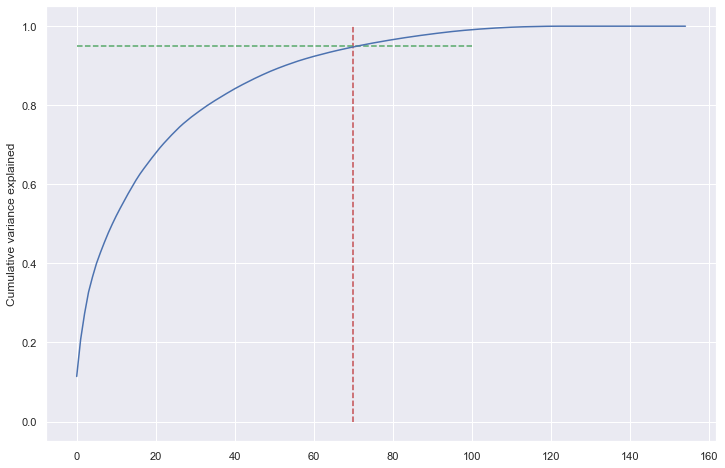

In [193]:
var_cumu = np.cumsum(pca.explained_variance_ratio_)
fig = plt.figure(figsize=[12,8])
plt.vlines(x=70, ymax=1, ymin=0, colors="r", linestyles="--")
plt.hlines(y=0.95, xmax=100, xmin=0, colors="g", linestyles="--")
plt.plot(var_cumu)
plt.ylabel("Cumulative variance explained")
plt.show()

We will take 70 components for our model

In [194]:
from sklearn.decomposition import IncrementalPCA
pca_final = IncrementalPCA(n_components=70)
df_train_pca = pca_final.fit_transform(X_train)
df_train_pca.shape

(21000, 70)

In [197]:
df_test_pca = pca_final.transform(X_test)
df_test_pca.shape

(9001, 70)

## Logistic Regression Using PCA

In [200]:
from sklearn.linear_model import LogisticRegression
learner_pca = LogisticRegression(class_weight='balanced')
model_pca = learner_pca.fit(df_train_pca, y_train)


In [202]:
y_train_pred=model_pca.predict(df_train_pca)
y_train_pred_pca = pd.DataFrame({'Churn':y_train.values, 'Churn_Pred':y_train_pred})
y_train_pred_pca['mobile_number'] = y_train.index
y_train_pred_pca.head()

,Churn,Churn_Pred,mobile_number
0,0,0,7001454064
1,0,0,7001929370
2,0,0,7000952221
3,0,0,7000752154
4,0,0,7000346259


In [203]:
y_test_lr_pca = model_pca.predict(df_test_pca)

In [207]:
# Confusion matrix 
confusion = metrics.confusion_matrix(y_train_pred_pca.Churn, y_train_pred_pca.Churn_Pred )
print(confusion)
print('Accuracy : {:.2f}'.format(metrics.accuracy_score(y_train_pred_pca.Churn, y_train_pred_pca.Churn_Pred)))
print('Precision Score : {:.2f}'.format(metrics.precision_score(y_train_pred_pca.Churn, y_train_pred_pca.Churn_Pred)))
print('Recall : {:.2f}'.format(metrics.recall_score(y_train_pred_pca.Churn, y_train_pred_pca.Churn_Pred)))
print('F1 Score : {:.2f}'.format(metrics.f1_score(y_train_pred_pca.Churn, y_train_pred_pca.Churn_Pred)))

[[15613  3696]
 [  275  1416]]
Accuracy : 0.81
Precision Score : 0.28
Recall : 0.84
F1 Score : 0.42


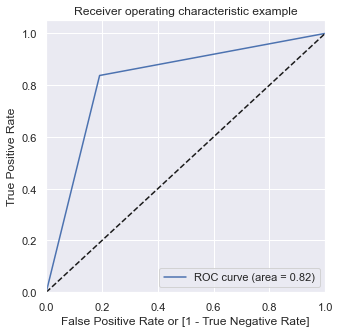

In [205]:
draw_roc(y_train_pred_pca.Churn, y_train_pred_pca.Churn_Pred)

Not Much Difference only our accuracy increase by 1% and Precision also increased.

## Random Forest Using PCA

In [208]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold
from sklearn.model_selection import GridSearchCV


In [211]:
#using default parameters
rfc = RandomForestClassifier(class_weight='balanced')
rfc.fit(X_train,y_train)
y_train_pred=rfc.predict(X_train)
y_train_pred_random_pca = pd.DataFrame({'Churn':y_train.values, 'Churn_Pred':y_train_pred})
y_train_pred_random_pca['mobile_number'] = y_train.index
y_train_pred_random_pca.head()

,Churn,Churn_Pred,mobile_number
0,0,0,7001454064
1,0,0,7001929370
2,0,0,7000952221
3,0,0,7000752154
4,0,0,7000346259


In [212]:
# Confusion matrix 
confusion = metrics.confusion_matrix(y_train_pred_random_pca.Churn, y_train_pred_random_pca.Churn_Pred )
print(confusion)
print('Accuracy : {:.2f}'.format(metrics.accuracy_score(y_train_pred_random_pca.Churn, y_train_pred_random_pca.Churn_Pred)))
print('Precision Score : {:.2f}'.format(metrics.precision_score(y_train_pred_random_pca.Churn, y_train_pred_random_pca.Churn_Pred)))
print('Recall : {:.2f}'.format(metrics.recall_score(y_train_pred_random_pca.Churn, y_train_pred_random_pca.Churn_Pred)))
print('F1 Score : {:.2f}'.format(metrics.f1_score(y_train_pred_random_pca.Churn, y_train_pred_random_pca.Churn_Pred)))


[[19309     0]
 [    0  1691]]
Accuracy : 1.00
Precision Score : 1.00
Recall : 1.00
F1 Score : 1.00


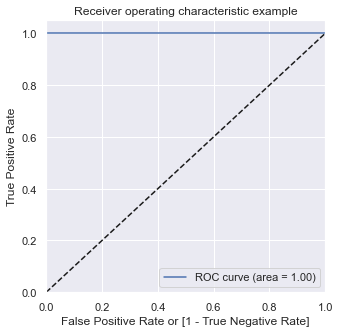

In [220]:
draw_roc(y_train_pred_random_pca.Churn, y_train_pred_random_pca.Churn_Pred)

### tunning random forest with hyperparameters

In [217]:
# Create the parameter grid based on the results of random search 
param_grid = {
    'max_depth': [4,8,10,15,20],
    'min_samples_leaf': range(100, 400, 200),
    'min_samples_split': range(200, 500, 200),
    'n_estimators': [100,200, 300], 
    'max_features': [5, 10,20,30]
}
# Create a based model
rf = RandomForestClassifier(class_weight='balanced')
# Instantiate the grid search model
grid_search = GridSearchCV(estimator = rf, param_grid = param_grid, 
                          cv = 3, n_jobs = -1,verbose = 1)

grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 240 candidates, totalling 720 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:   12.0s
[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed:  2.5min
[Parallel(n_jobs=-1)]: Done 426 tasks      | elapsed:  8.4min
[Parallel(n_jobs=-1)]: Done 720 out of 720 | elapsed: 15.7min finished


GridSearchCV(cv=3, estimator=RandomForestClassifier(class_weight='balanced'),
             n_jobs=-1,
             param_grid={'max_depth': [4, 8, 10, 15, 20],
                         'max_features': [5, 10, 20, 30],
                         'min_samples_leaf': range(100, 400, 200),
                         'min_samples_split': range(200, 500, 200),
                         'n_estimators': [100, 200, 300]},
             verbose=1)

In [218]:
# printing the optimal accuracy score and hyperparameters
print('We can get accuracy of',grid_search.best_score_,'using',grid_search.best_params_)

We can get accuracy of 0.8981428571428571 using {'max_depth': 4, 'max_features': 10, 'min_samples_leaf': 100, 'min_samples_split': 200, 'n_estimators': 100}


In [221]:
#fitting our model with best hyperparameters
# model with the best hyperparameters
rfc = RandomForestClassifier(bootstrap=True,class_weight='balanced',
                             max_depth=4,
                             min_samples_leaf=100, 
                             min_samples_split=200,
                             max_features=10,
                             n_estimators=100)

In [222]:
rfc.fit(X_train,y_train)
y_train_pred=rfc.predict(X_train)
y_train_pred_random_pca = pd.DataFrame({'Churn':y_train.values, 'Churn_Pred':y_train_pred})
y_train_pred_random_pca['mobile_number'] = y_train.index
y_train_pred_random_pca.head()

,Churn,Churn_Pred,mobile_number
0,0,0,7001454064
1,0,0,7001929370
2,0,0,7000952221
3,0,0,7000752154
4,0,0,7000346259


In [223]:
# Confusion matrix 
confusion = metrics.confusion_matrix(y_train_pred_random_pca.Churn, y_train_pred_random_pca.Churn_Pred )
print(confusion)
print('Accuracy : {:.2f}'.format(metrics.accuracy_score(y_train_pred_random_pca.Churn, y_train_pred_random_pca.Churn_Pred)))
print('Precision Score : {:.2f}'.format(metrics.precision_score(y_train_pred_random_pca.Churn, y_train_pred_random_pca.Churn_Pred)))
print('Recall : {:.2f}'.format(metrics.recall_score(y_train_pred_random_pca.Churn, y_train_pred_random_pca.Churn_Pred)))
print('F1 Score : {:.2f}'.format(metrics.f1_score(y_train_pred_random_pca.Churn, y_train_pred_random_pca.Churn_Pred)))


[[17724  1585]
 [  438  1253]]
Accuracy : 0.90
Precision Score : 0.44
Recall : 0.74
F1 Score : 0.55


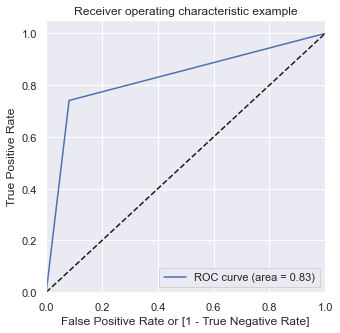

In [225]:
draw_roc(y_train_pred_random_pca.Churn, y_train_pred_random_pca.Churn_Pred)